<a href="https://colab.research.google.com/github/bayan-Alharbi/adhd-app/blob/main/Cross_population_v4_cnn_threshold_FIXED3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ─── Step 1: Libraries ──────────────────────────────────────────────────────
!pip install kaggle kagglehub scikit-learn xgboost -q

import scipy.io, numpy as np, pandas as pd, re, os, random, warnings
warnings.filterwarnings('ignore')
from scipy import signal
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score,
                             f1_score, precision_score, recall_score)
from sklearn.feature_selection import SelectKBest, f_classif
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
print('Libraries ready | TF:', tf.__version__)


Libraries ready | TF: 2.20.0


In [ ]:
# ─── Step 2: Load Datasets ──────────────────────────────────────────────────
import kagglehub
from google.colab import files

print('Upload kaggle.json:')
uploaded = files.upload()
os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('/content/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

!kaggle datasets download -d andreslopezb/mendeley-data-eeg-adhd-gcpds \
    --unzip -p /content/eeg_dataset -q
print('EEG Dataset ready!')

path_hyp = kagglehub.dataset_download('arashnic/adhd-diagnosis-data')
print('Hyperaktiv Dataset ready!')


Upload kaggle.json:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/andreslopezb/mendeley-data-eeg-adhd-gcpds
License(s): CC-BY-SA-4.0
EEG Dataset ready!
Using Colab cache for faster access to the 'adhd-diagnosis-data' dataset.
Hyperaktiv Dataset ready!


In [ ]:
# ─── Step 3: EEG — Subject-Level Functions ──────────────────────────────────
# الإصلاح الأساسي:
# بدلاً من windowing على كامل الداتا ثم التقسيم،
# نقسّم الأشخاص أولاً ثم نطبّق الـ windowing على كل split منفصل.
# هكذا نضمن أن نوافذ نفس الشخص لا تظهر في train و test معاً.

BASE = '/content/eeg_dataset/MENDELEY_DATA_EEG_ADHD_GCPDS'
FS   = 256  # FIX: dataset's official sampling rate is 256 Hz (Mendeley docs), was wrongly 128

MADHD = scipy.io.loadmat(f'{BASE}/MADHD.mat')['MADHD'][0][0]
FADHD = scipy.io.loadmat(f'{BASE}/FADHD.mat')['FADHD'][0][0]
MC    = scipy.io.loadmat(f'{BASE}/MC.mat')['MC'][0][0]
FC    = scipy.io.loadmat(f'{BASE}/FC.mat')['FC'][0][0]

def bandpass(data, lo=1.0, hi=45.0, fs=256, order=4):  # FIX: fs 128 -> 256
    nyq  = fs / 2
    b, a = signal.butter(order, [lo/nyq, hi/nyq], btype='band')
    return signal.filtfilt(b, a, data, axis=0)

def notch(data, freq=50.0, fs=256, Q=30):  # FIX: fs 128 -> 256
    b, a = signal.iirnotch(freq/(fs/2), Q)
    return signal.filtfilt(b, a, data, axis=0)

def windows_for_subject(sig, win_len=512, step=256):  # FIX: preserve original 2-second window duration at true 256Hz (was 256/128 under wrong fs)
    """ترجع قائمة النوافذ لشخص واحد فقط."""
    sig  = bandpass(sig)
    sig  = notch(sig)
    wins = []
    for start in range(0, sig.shape[0] - win_len + 1, step):
        w = sig[start:start+win_len, :]
        if np.max(np.abs(w)) >= 150:
            continue
        w_norm = (w - w.mean(axis=0)) / (w.std(axis=0) + 1e-8)
        wins.append(w_norm)
    return wins

# بناء قائمة الأشخاص مع لاباتهم
subjects_adhd = [(MADHD[i], 1) for i in range(MADHD.shape[0])] + \
                [(FADHD[i], 1) for i in range(FADHD.shape[0])]
subjects_ctrl = [(MC[i], 0) for i in range(MC.shape[0])] + \
                [(FC[i], 0) for i in range(FC.shape[0])]
all_subjects  = subjects_adhd + subjects_ctrl
subj_labels   = np.array([s[1] for s in all_subjects])

print(f'Total subjects → ADHD: {sum(subj_labels==1)} | Control: {sum(subj_labels==0)}')


Total subjects → ADHD: 38 | Control: 42


In [ ]:
# ─── Step 4: Subject-Level Train/Test Split (EEG) ───────────────────────────
subj_indices = np.arange(len(all_subjects))
train_subj_idx, test_subj_idx = train_test_split(
    subj_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=subj_labels
)

def build_windows_from_indices(indices, subjects):
    """يولّد النوافذ فقط للأشخاص المحددة بالـ indices."""
    X_list, y_list, subj_id_list = [], [], []
    for sid in indices:
        sig, label = subjects[sid]
        wins = windows_for_subject(sig.copy())
        for w in wins:
            X_list.append(w)
            y_list.append(label)
            subj_id_list.append(sid)
    return np.array(X_list), np.array(y_list), np.array(subj_id_list)

print('Generating EEG windows (train subjects)...')
Xeeg_tr, yeeg_tr, subj_tr = build_windows_from_indices(train_subj_idx, all_subjects)
print('Generating EEG windows (test subjects)...')
Xeeg_te, yeeg_te, subj_te = build_windows_from_indices(test_subj_idx,  all_subjects)

print(f'EEG Train: {Xeeg_tr.shape} | ADHD={sum(yeeg_tr==1)} | Control={sum(yeeg_tr==0)}')
print(f'EEG Test : {Xeeg_te.shape} | ADHD={sum(yeeg_te==1)} | Control={sum(yeeg_te==0)}')
print(f'Train subjects: {len(train_subj_idx)} | Test subjects: {len(test_subj_idx)}')


Generating EEG windows (train subjects)...
Generating EEG windows (test subjects)...
EEG Train: (1933, 512, 2) | ADHD=897 | Control=1036
EEG Test : (315, 512, 2) | ADHD=141 | Control=174
Train subjects: 68 | Test subjects: 12


In [ ]:
# ─── Step 5: Hyperaktiv Preprocessing ───────────────────────────────────────
dataX = pd.read_csv(f'{path_hyp}/features.csv',     sep=';').sort_values('ID')
dataY = pd.read_csv(f'{path_hyp}/patient_info.csv', sep=';').sort_values('ID')

dataX = dataX.fillna(0)
dataX = dataX.rename(columns=lambda x: re.sub(r'[",]', '', x))
dataY = dataY.rename(columns=lambda x: re.sub(r'[",]', '', x))

dataY = dataY[dataY['ID'].isin(dataX['ID'])]
dataX = dataX[dataX['ID'].isin(dataY['ID'])]
dataX = dataX.set_index('ID')
dataY = dataY.set_index('ID')['ADHD'].copy()

selector = SelectKBest(score_func=f_classif, k=50)
selector.fit(dataX, dataY)
dataX = dataX[dataX.columns[selector.get_support()]]

scaler_hyp = StandardScaler()
dataX[dataX.columns] = scaler_hyp.fit_transform(dataX)

X_hyp = dataX.values
y_hyp = dataY.values

Xhyp_tr, Xhyp_te, yhyp_tr, yhyp_te = train_test_split(
    X_hyp, y_hyp, test_size=0.20, random_state=SEED, stratify=y_hyp
)
print(f'Hyperaktiv: {X_hyp.shape}, ADHD={sum(y_hyp==1)}, Control={sum(y_hyp==0)}')
print(f'HYP Train: {Xhyp_tr.shape} | Test: {Xhyp_te.shape}')


Hyperaktiv: (85, 50), ADHD=45, Control=40
HYP Train: (68, 50) | Test: (17, 50)


In [ ]:
# ─── Step 6: Build CNN ───────────────────────────────────────────────────────
def build_cnn(input_shape=(512, 2)):  # FIX: matches corrected win_len=512
    inp = layers.Input(shape=input_shape)
    x   = layers.Conv1D(64,  7, padding='same', activation='relu')(inp)
    x   = layers.BatchNormalization()(x)
    x   = layers.MaxPooling1D(2)(x)
    x   = layers.Dropout(0.2)(x)
    x   = layers.Conv1D(128, 5, padding='same', activation='relu')(x)
    x   = layers.BatchNormalization()(x)
    x   = layers.MaxPooling1D(2)(x)
    x   = layers.Dropout(0.2)(x)
    x   = layers.Conv1D(256, 3, padding='same', activation='relu')(x)
    x   = layers.BatchNormalization()(x)
    x   = layers.GlobalAveragePooling1D()(x)
    x   = layers.Dense(128, activation='relu',
                       kernel_regularizer=regularizers.l2(1e-4))(x)
    x   = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    m   = models.Model(inp, out, name='CNN_EEG')
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return m


In [ ]:
# ─── Step 7: Train CNN (Base Model) ─────────────────────────────────────────
Xeeg_tr2, Xeeg_val, yeeg_tr2, yeeg_val = train_test_split(
    Xeeg_tr, yeeg_tr, test_size=0.176, random_state=SEED, stratify=yeeg_tr
)

cb = [
    callbacks.EarlyStopping(monitor='val_auc', patience=15,
                            restore_best_weights=True, mode='max'),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7)
]

print('Training CNN (EEG Base Model)...')
cnn_model = build_cnn()
cnn_model.fit(Xeeg_tr2, yeeg_tr2,
              validation_data=(Xeeg_val, yeeg_val),
              epochs=60, batch_size=64, callbacks=cb, verbose=1)
print('CNN done!')


Training CNN (EEG Base Model)...
Epoch 1/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 32s 583ms/step - accuracy: 0.8731 - auc: 0.9476 - loss: 0.3298 - val_accuracy: 0.5484 - val_auc: 0.9497 - val_loss: 0.6518 - learning_rate: 0.0010
Epoch 2/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.9234 - auc: 0.9730 - loss: 0.2268 - val_accuracy: 0.4633 - val_auc: 0.9597 - val_loss: 1.0441 - learning_rate: 0.0010
Epoch 3/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9347 - auc: 0.9795 - loss: 0.1980 - val_accuracy: 0.4633 - val_auc: 0.9441 - val_loss: 1.6632 - learning_rate: 0.0010
Epoch 4/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9441 - auc: 0.9845 - loss: 0.1746 - val_accuracy: 0.4633 - val_auc: 0.9396 - val_loss: 2.2871 - learning_rate: 0.0010
Epoch 5/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9428 - auc: 0.9857 - loss: 0.1676 - val_accuracy: 0.4633 - val_auc: 0.5763 - val_loss: 3.3427 - learning_rate: 0.0010
Epoch 6/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/ste

In [ ]:
# ─── Step 7b: CNN Optimal Threshold (Youden's J on validation set) ─────────
# المشكلة: بعد تصحيح fs، مخرجات الـ CNN صارت منحازة فوق 0.5 (AUC ممتاز لكن
# threshold=0.5 ما عاد يميز جيدًا). نحسب أفضل threshold من الـ validation
# set نفسه (Xeeg_val/yeeg_val) — بدون أي لمس لبيانات الاختبار — ونستخدمه
# فقط لتقييم الـ CNN.

p_eeg_val = cnn_model.predict(Xeeg_val, verbose=0).ravel()
fpr_v, tpr_v, thr_v = roc_curve(yeeg_val, p_eeg_val)
youden_j = tpr_v - fpr_v
best_idx = np.argmax(youden_j)
CNN_OPTIMAL_THRESHOLD = thr_v[best_idx]

print(f'CNN optimal threshold (Youden\'s J, from validation set): {CNN_OPTIMAL_THRESHOLD:.4f}')
print(f'  (val TPR={tpr_v[best_idx]:.3f}, val FPR={fpr_v[best_idx]:.3f}, val AUC={roc_auc_score(yeeg_val, p_eeg_val):.3f})')


CNN optimal threshold (Youden's J, from validation set): 0.8829
  (val TPR=0.937, val FPR=0.109, val AUC=0.961)


In [ ]:
# ─── Step 8: Train LR (Hyperaktiv Base Model) ───────────────────────────────
lr_base = LogisticRegression(C=100, penalty='l1', solver='liblinear',
                             class_weight='balanced', max_iter=5000,
                             random_state=SEED)
lr_base.fit(Xhyp_tr, yhyp_tr)
print('Logistic Regression (Hyperaktiv Base Model) done!')

Logistic Regression (Hyperaktiv Base Model) done!


In [ ]:
# ─── STEP 9 - OOF predictions, subject-level GroupKFold ─────────────────────

print('Generating OOF predictions (Subject-Level GroupKFold)...')

# NOTE: N_FOLDS and gkf were not defined anywhere in steps_09_to_14_final.py
# (they were assumed to already exist from an earlier run). Kept here from
# the original notebook cell so this cell can actually run standalone.
N_FOLDS = 5
gkf     = GroupKFold(n_splits=N_FOLDS)

oof_eeg_prob = np.zeros(len(Xeeg_tr))
oof_eeg_label = yeeg_tr.copy()

fold_models = []                                                  # [EDIT 1]

for fold, (tr_idx, val_idx) in enumerate(
        gkf.split(Xeeg_tr, yeeg_tr, groups=subj_tr)):

    print(f'  EEG Fold {fold + 1}/{N_FOLDS} '
          f'| train windows={len(tr_idx)} | val windows={len(val_idx)}')

    X_tr_f, X_val_f = Xeeg_tr[tr_idx], Xeeg_tr[val_idx]
    y_tr_f = yeeg_tr[tr_idx]

    m_fold = build_cnn()
    cb_fold = [callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                       restore_best_weights=True)]
    m_fold.fit(X_tr_f, y_tr_f,
               validation_data=(X_val_f, yeeg_tr[val_idx]),
               epochs=40, batch_size=64, callbacks=cb_fold, verbose=0)

    oof_eeg_prob[val_idx] = m_fold.predict(X_val_f, verbose=0).ravel()
    fold_models.append(m_fold)                                    # [EDIT 1]

EEG_OOF_AUC = roc_auc_score(oof_eeg_label, oof_eeg_prob)
print(f'  EEG OOF AUC: {EEG_OOF_AUC:.3f}')

# Behavioral OOF, unchanged
oof_hyp_prob = np.zeros(len(Xhyp_tr))
oof_hyp_label = yhyp_tr.copy()

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for tr_idx, val_idx in skf.split(Xhyp_tr, yhyp_tr):
    m_fold = LogisticRegression(C=100, penalty='l1', solver='liblinear',
                                class_weight='balanced', max_iter=5000,
                                random_state=SEED)
    m_fold.fit(Xhyp_tr[tr_idx], yhyp_tr[tr_idx])
    oof_hyp_prob[val_idx] = m_fold.predict_proba(Xhyp_tr[val_idx])[:, 1]

HYP_OOF_AUC = roc_auc_score(oof_hyp_label, oof_hyp_prob)
print(f'  HYP OOF AUC: {HYP_OOF_AUC:.3f}')


Generating OOF predictions (Subject-Level GroupKFold)...
  EEG Fold 1/5 | train windows=1536 | val windows=397
  EEG Fold 2/5 | train windows=1558 | val windows=375
  EEG Fold 3/5 | train windows=1543 | val windows=390
  EEG Fold 4/5 | train windows=1559 | val windows=374
  EEG Fold 5/5 | train windows=1536 | val windows=397
  EEG OOF AUC: 0.836
  HYP OOF AUC: 0.839


In [ ]:
# ─── STEP 10 - META dataset, four columns ────────────────────────────────────

eeg_rows = np.column_stack([
    oof_eeg_prob,
    np.full(len(oof_eeg_prob), 0.5),
    np.ones(len(oof_eeg_prob)),      # has_eeg = 1
    np.zeros(len(oof_eeg_prob))      # has_hyp = 0
])

hyp_rows = np.column_stack([
    np.full(len(oof_hyp_prob), 0.5),
    oof_hyp_prob,
    np.zeros(len(oof_hyp_prob)),     # has_eeg = 0
    np.ones(len(oof_hyp_prob))       # has_hyp = 1
])

X_meta_train = np.vstack([eeg_rows, hyp_rows])
y_meta_train = np.concatenate([oof_eeg_label, oof_hyp_label])

hyp_weight = len(eeg_rows) / len(hyp_rows)
sample_weights = np.concatenate([
    np.ones(len(eeg_rows)),
    np.full(len(hyp_rows), hyp_weight)
])

print(f'\nMETA training set: {X_meta_train.shape}')
print(f'EEG rows: {len(eeg_rows)} (weight=1.0) | '
      f'HYP rows: {len(hyp_rows)} (weight={hyp_weight:.1f})')



META training set: (2001, 4)
EEG rows: 1933 (weight=1.0) | HYP rows: 68 (weight=28.4)


In [ ]:
# ─── STEP 11 - Train META model ──────────────────────────────────────────────

meta_model = LogisticRegression(C=1.0, class_weight='balanced',
                                max_iter=1000, random_state=SEED)
meta_model.fit(X_meta_train, y_meta_train, sample_weight=sample_weights)

c = meta_model.coef_[0]
b0 = meta_model.intercept_[0]

print('\nMETA Model trained!')
print(f'  z = {b0:.3f} + {c[0]:.3f}*p_eeg + {c[1]:.3f}*p_hyp '
      f'+ {c[2]:.3f}*has_eeg + {c[3]:.3f}*has_hyp')



META Model trained!
  z = -8.372 + 12.891*p_eeg + 1.944*p_hyp + -1.227*has_eeg + 1.243*has_hyp


In [ ]:
# ─── STEP 12 - Evaluate ───────────────────────────────────────────────────────

# [EDIT 2] Predict with the fold ensemble, not the separate cnn_model.
p_eeg_test = np.mean(
    [m.predict(Xeeg_te, verbose=0).ravel() for m in fold_models],
    axis=0
)
p_hyp_test = lr_base.predict_proba(Xhyp_te)[:, 1]

# [EDIT 2] Youden's J point on the OOF probabilities. Reported in the Method
# section as the operating point the base model would use on its own. No test
# data is touched.
fpr_o, tpr_o, thr_o = roc_curve(oof_eeg_label, oof_eeg_prob)
ENSEMBLE_THRESHOLD = thr_o[np.argmax(tpr_o - fpr_o)]

# [EDIT 4] The META model's own implied cut on p_eeg. Solving
#   z = b0 + b1*p_eeg + b2*0.5 + b3*1 + b4*0 = 0
# gives the p_eeg value at which META flips to ADHD. Both CNN and META are
# scored here so the EEG comparison is like for like.
CNN_EVAL_THRESHOLD = -(b0 + 0.5 * c[1] + c[2]) / c[0]

print(f'\nOOF Youden threshold (base model)   : {ENSEMBLE_THRESHOLD:.4f}')
print(f'Shared evaluation threshold (= META): {CNN_EVAL_THRESHOLD:.4f}')

X_meta_eeg_test = np.column_stack([
    p_eeg_test,
    np.full(len(p_eeg_test), 0.5),
    np.ones(len(p_eeg_test)),
    np.zeros(len(p_eeg_test))
])

X_meta_hyp_test = np.column_stack([
    np.full(len(p_hyp_test), 0.5),
    p_hyp_test,
    np.zeros(len(p_hyp_test)),
    np.ones(len(p_hyp_test))
])

X_meta_test = np.vstack([X_meta_eeg_test, X_meta_hyp_test])
y_meta_test = np.concatenate([yeeg_te, yhyp_te])


def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    auc = roc_auc_score(y_true, y_prob)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    cm = confusion_matrix(y_true, y_pred)
    print(f'\n{name}')
    print(f'  Acc={acc*100:.1f}%  Prec={prec*100:.1f}%  '
          f'Rec={rec*100:.1f}%  F1={f1*100:.1f}%  AUC={auc:.3f}')
    return dict(name=name, acc=acc, prec=prec, rec=rec,
                f1=f1, auc=auc, fpr=fpr, tpr=tpr, cm=cm)


print('\n' + '=' * 65)
print('  EVALUATION (held-out test subjects, window level)')
print('=' * 65)

r_cnn = evaluate('CNN (EEG only)', yeeg_te, p_eeg_test,
                 threshold=CNN_EVAL_THRESHOLD)                    # [EDIT 4]
r_lr = evaluate('LR (Hyperaktiv only)', yhyp_te, p_hyp_test)
r_meta = evaluate('META (Late Fusion - combined)', y_meta_test,
                  meta_model.predict_proba(X_meta_test)[:, 1])
r_meta_eeg = evaluate('META on EEG test', yeeg_te,
                      meta_model.predict_proba(X_meta_eeg_test)[:, 1])
r_meta_hyp = evaluate('META on HYP test', yhyp_te,
                      meta_model.predict_proba(X_meta_hyp_test)[:, 1])


# -----------------------------------------------------------------------------
# Diagnostic: decision boundaries
# -----------------------------------------------------------------------------
hyp_cut = -(b0 + 0.5 * c[0] + c[3]) / c[1]

print('\n' + '=' * 65)
print('  META DECISION BOUNDARY')
print('=' * 65)
print(f'  Implied p_eeg cutoff : {CNN_EVAL_THRESHOLD:.4f}')
print(f'  Implied p_hyp cutoff : {hyp_cut:.4f}')
print(f'  OOF Youden point     : {ENSEMBLE_THRESHOLD:.4f}')
print('=' * 65)



OOF Youden threshold (base model)   : 0.6425
Shared evaluation threshold (= META): 0.6692

  EVALUATION (held-out test subjects, window level)

CNN (EEG only)
  Acc=94.9%  Prec=89.8%  Rec=100.0%  F1=94.6%  AUC=1.000

LR (Hyperaktiv only)
  Acc=82.4%  Prec=80.0%  Rec=88.9%  F1=84.2%  AUC=0.958

META (Late Fusion - combined)
  Acc=94.3%  Prec=89.2%  Rec=99.3%  F1=94.0%  AUC=0.990

META on EEG test
  Acc=94.9%  Prec=89.8%  Rec=100.0%  F1=94.6%  AUC=1.000

META on HYP test
  Acc=82.4%  Prec=80.0%  Rec=88.9%  F1=84.2%  AUC=0.958

  META DECISION BOUNDARY
  Implied p_eeg cutoff : 0.6692
  Implied p_hyp cutoff : 0.3516
  OOF Youden point     : 0.6425


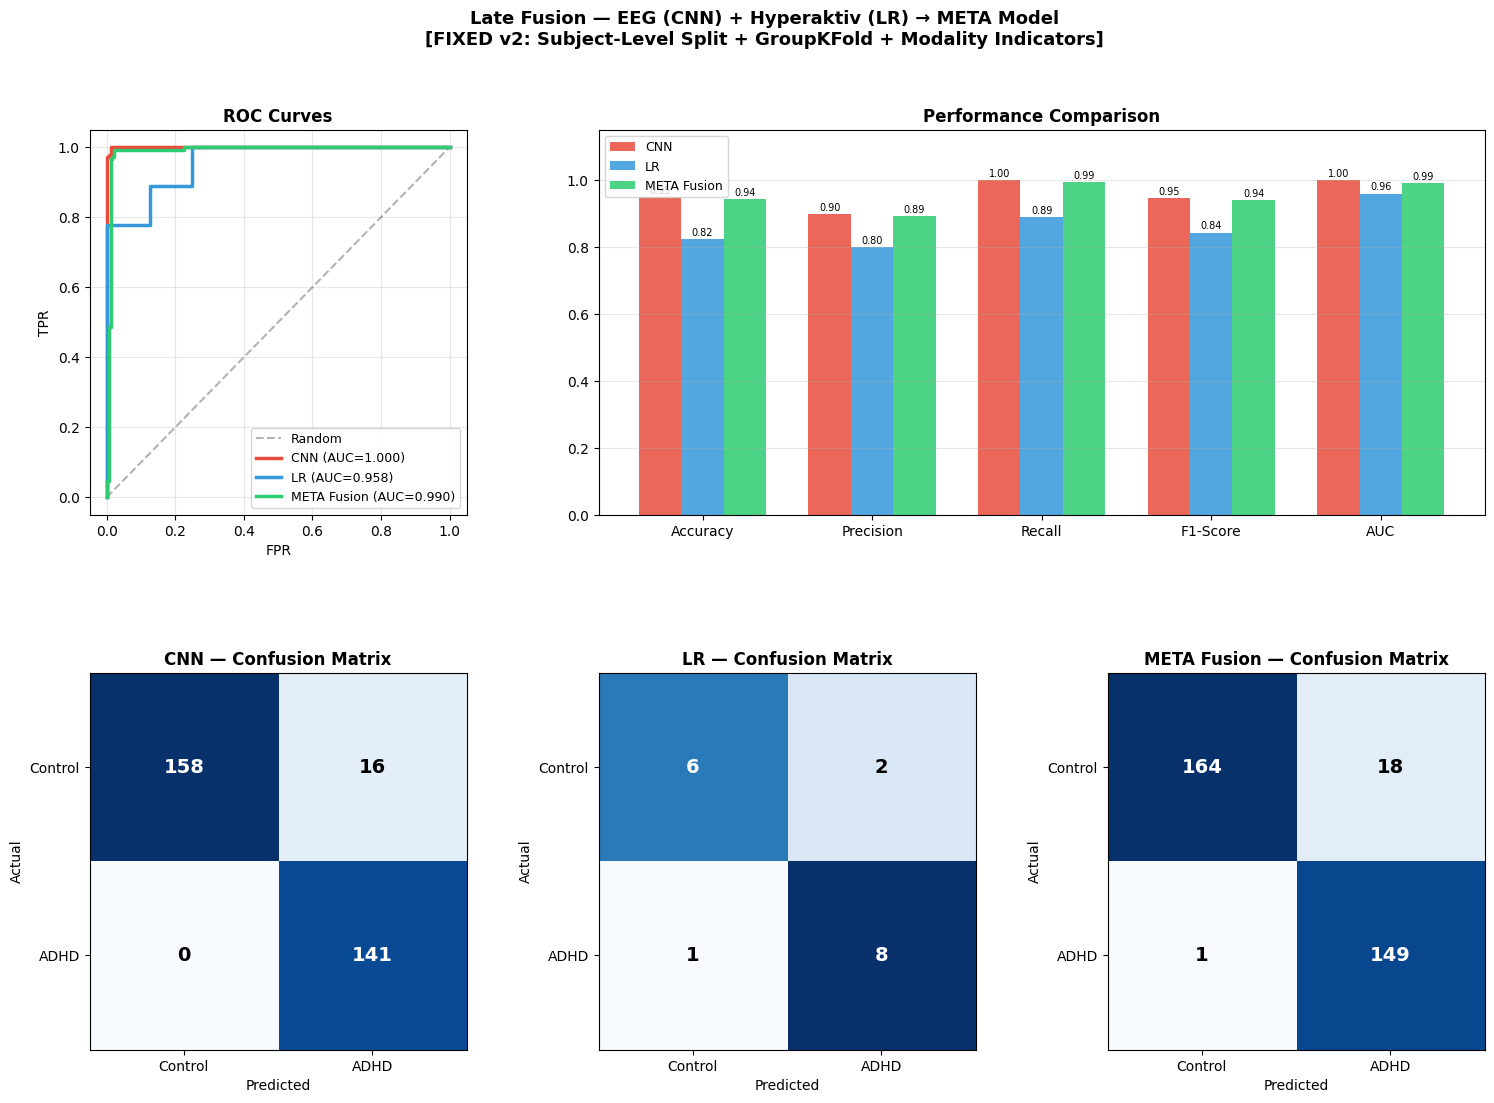

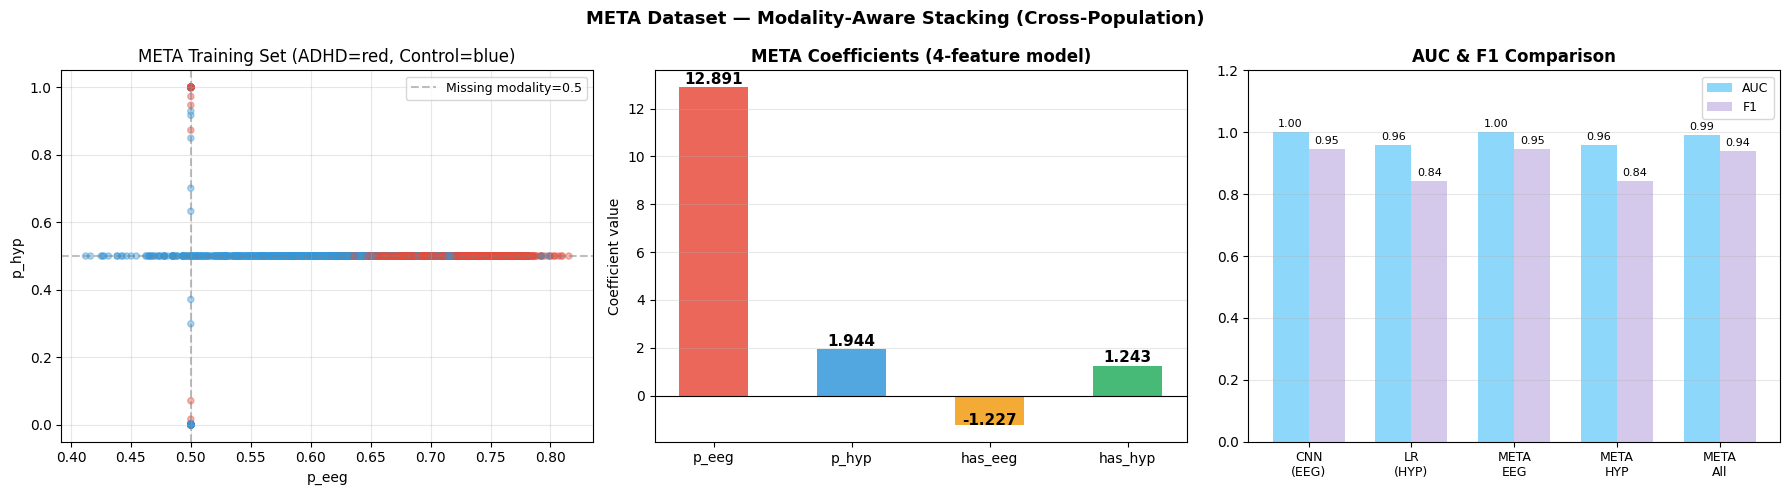


 SUMMARY (FIXED v2 — Modality Indicators)
  CNN (EEG only)     → AUC: 1.000 | F1: 94.6%
  LR  (Hyperaktiv)   → AUC: 0.958  | F1: 84.2%
  META (Late Fusion) → AUC: 0.990 | F1: 94.0%


In [ ]:
# ─── Step 13: Visualizations ────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'Late Fusion — EEG (CNN) + Hyperaktiv (LR) → META Model\n'
    '[FIXED v2: Subject-Level Split + GroupKFold + Modality Indicators]',
    fontsize=13, fontweight='bold'
)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

COLORS = {
    'CNN (EEG)':      '#E74C3C',
    'LR (Hyperaktiv)':'#3498DB',
    'META Fusion':    '#2ECC71'
}
all_res = [
    ('CNN (EEG)',       r_cnn,  yeeg_te,      p_eeg_test),
    ('LR (Hyperaktiv)', r_lr,   yhyp_te,      p_hyp_test),
    ('META Fusion',     r_meta, y_meta_test,
     meta_model.predict_proba(X_meta_test)[:, 1]),
]

# ROC Curves
ax_roc = fig.add_subplot(gs[0, 0])
ax_roc.plot([0,1],[0,1],'k--', alpha=0.3, label='Random')
for lbl, r, _, _ in all_res:
    ax_roc.plot(r['fpr'], r['tpr'], lw=2.5, color=COLORS[lbl],
                label=f"{lbl.split('(')[0].strip()} (AUC={r['auc']:.3f})")
ax_roc.set_title('ROC Curves', fontweight='bold')
ax_roc.set_xlabel('FPR'); ax_roc.set_ylabel('TPR')
ax_roc.legend(fontsize=9); ax_roc.grid(True, alpha=0.3)

# Bar chart
ax_bar = fig.add_subplot(gs[0, 1:])
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
x = np.arange(len(metrics_names))
w = 0.25
for i, (lbl, r, _, _) in enumerate(all_res):
    vals = [r['acc'], r['prec'], r['rec'], r['f1'], r['auc']]
    bars = ax_bar.bar(x + (i-1)*w, vals, w,
                      color=COLORS[lbl], alpha=0.85,
                      label=lbl.split('(')[0].strip())
    for bar, v in zip(bars, vals):
        ax_bar.text(bar.get_x()+bar.get_width()/2,
                    bar.get_height()+0.005,
                    f'{v:.2f}', ha='center', va='bottom', fontsize=7)
ax_bar.set_xticks(x); ax_bar.set_xticklabels(metrics_names)
ax_bar.set_ylim(0, 1.15)
ax_bar.set_title('Performance Comparison', fontweight='bold')
ax_bar.legend(fontsize=9); ax_bar.grid(True, alpha=0.3, axis='y')

# Confusion Matrices
for col, (lbl, r, _, _) in enumerate(all_res):
    ax_cm = fig.add_subplot(gs[1, col])
    cm    = r['cm']
    ax_cm.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax_cm.text(j, i, str(cm[i,j]), ha='center', va='center',
                       fontsize=14, fontweight='bold',
                       color='white' if cm[i,j] > cm.max()/2 else 'black')
    ax_cm.set_xticks([0,1]); ax_cm.set_yticks([0,1])
    ax_cm.set_xticklabels(['Control','ADHD'])
    ax_cm.set_yticklabels(['Control','ADHD'])
    ax_cm.set_xlabel('Predicted'); ax_cm.set_ylabel('Actual')
    ax_cm.set_title(f"{lbl.split('(')[0].strip()} — Confusion Matrix",
                    fontweight='bold')

plt.savefig('late_fusion_results_FIXED_v2.png', dpi=150, bbox_inches='tight')
plt.show()


# ─── META Analysis Plot ──────────────────────────────────────────────────────
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle('META Dataset — Modality-Aware Stacking (Cross-Population)',
              fontweight='bold', fontsize=13)

# Scatter: p_eeg vs p_hyp
colors_scatter = ['#E74C3C' if l==1 else '#3498DB' for l in y_meta_train]
axes2[0].scatter(X_meta_train[:,0], X_meta_train[:,1],
                 c=colors_scatter, alpha=0.4, s=20)
axes2[0].axvline(0.5, color='gray', ls='--', alpha=0.5, label='Missing modality=0.5')
axes2[0].axhline(0.5, color='gray', ls='--', alpha=0.5)
axes2[0].set_xlabel('p_eeg'); axes2[0].set_ylabel('p_hyp')
axes2[0].set_title('META Training Set (ADHD=red, Control=blue)')
axes2[0].legend(fontsize=9); axes2[0].grid(True, alpha=0.3)

# Coefficients bar
coef_vals  = meta_model.coef_[0]
coef_names = ['p_eeg', 'p_hyp', 'has_eeg', 'has_hyp']
bar_colors = ['#E74C3C', '#3498DB', '#F39C12', '#27AE60']
bars = axes2[1].bar(coef_names, coef_vals, color=bar_colors, alpha=0.85, width=0.5)
for bar, v in zip(bars, coef_vals):
    axes2[1].text(bar.get_x()+bar.get_width()/2,
                  bar.get_height() + (0.02 if v >= 0 else -0.15),
                  f'{v:.3f}', ha='center', va='bottom',
                  fontsize=11, fontweight='bold')
axes2[1].axhline(0, color='black', lw=0.8)
axes2[1].set_title('META Coefficients (4-feature model)', fontweight='bold')
axes2[1].set_ylabel('Coefficient value')
axes2[1].grid(True, alpha=0.3, axis='y')

# Summary bar — AUC + F1
models_names = ['CNN\n(EEG)', 'LR\n(HYP)', 'META\nEEG', 'META\nHYP', 'META\nAll']
aucs_s = [r_cnn['auc'], r_lr['auc'], r_meta_eeg['auc'], r_meta_hyp['auc'], r_meta['auc']]
f1s_s  = [r_cnn['f1'],  r_lr['f1'],  r_meta_eeg['f1'],  r_meta_hyp['f1'],  r_meta['f1']]
x3 = np.arange(len(models_names))
w3 = 0.35
b1 = axes2[2].bar(x3 - w3/2, aucs_s, w3, color='#81D4FA', alpha=0.9, label='AUC')
b2 = axes2[2].bar(x3 + w3/2, f1s_s,  w3, color='#D1C4E9', alpha=0.9, label='F1')
for bar, v in list(zip(b1, aucs_s)) + list(zip(b2, f1s_s)):
    axes2[2].text(bar.get_x()+bar.get_width()/2,
                  bar.get_height()+0.01,
                  f'{v:.2f}', ha='center', va='bottom', fontsize=8)
axes2[2].set_xticks(x3); axes2[2].set_xticklabels(models_names, fontsize=9)
axes2[2].set_ylim(0, 1.2)
axes2[2].set_title('AUC & F1 Comparison', fontweight='bold')
axes2[2].legend(fontsize=9); axes2[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('meta_model_analysis_FIXED_v2.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n' + '='*65)
print(' SUMMARY (FIXED v2 — Modality Indicators)')
print('='*65)
print(f'  CNN (EEG only)     → AUC: {r_cnn["auc"]:.3f} | F1: {r_cnn["f1"]*100:.1f}%')
print(f'  LR  (Hyperaktiv)   → AUC: {r_lr["auc"]:.3f}  | F1: {r_lr["f1"]*100:.1f}%')
print(f'  META (Late Fusion) → AUC: {r_meta["auc"]:.3f} | F1: {r_meta["f1"]*100:.1f}%')
print('='*65)


In [ ]:
# ─── STEP 14 - Subject-level evaluation ──────────────────────────────────────

subj_eeg_prob, subj_eeg_label = [], []
for sid in test_subj_idx:
    mask = (subj_te == sid)
    if mask.sum() == 0:
        continue
    subj_eeg_prob.append(p_eeg_test[mask].mean())
    subj_eeg_label.append(yeeg_te[mask][0])
subj_eeg_prob = np.array(subj_eeg_prob)
subj_eeg_label = np.array(subj_eeg_label)

subj_hyp_prob = p_hyp_test.copy()
subj_hyp_label = yhyp_te.copy()

X_meta_subj_eeg = np.column_stack([
    subj_eeg_prob,
    np.full(len(subj_eeg_prob), 0.5),
    np.ones(len(subj_eeg_prob)),
    np.zeros(len(subj_eeg_prob))
])
X_meta_subj_hyp = np.column_stack([
    np.full(len(subj_hyp_prob), 0.5),
    subj_hyp_prob,
    np.zeros(len(subj_hyp_prob)),
    np.ones(len(subj_hyp_prob))
])

meta_subj_eeg_prob = meta_model.predict_proba(X_meta_subj_eeg)[:, 1]
meta_subj_hyp_prob = meta_model.predict_proba(X_meta_subj_hyp)[:, 1]

X_meta_subj_all = np.vstack([X_meta_subj_eeg, X_meta_subj_hyp])
y_meta_subj_all = np.concatenate([subj_eeg_label, subj_hyp_label])
meta_subj_all_prob = meta_model.predict_proba(X_meta_subj_all)[:, 1]


def evaluate_subj(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    auc = roc_auc_score(y_true, y_prob)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    cm = confusion_matrix(y_true, y_pred)
    n = len(y_true)
    print(f'\n{name} [n={n} subjects]')
    print(f'  Acc={acc*100:.1f}%  Prec={prec*100:.1f}%  '
          f'Rec={rec*100:.1f}%  F1={f1*100:.1f}%  AUC={auc:.3f}')
    return dict(name=name, acc=acc, prec=prec, rec=rec,
                f1=f1, auc=auc, fpr=fpr, tpr=tpr, cm=cm, n=n)


print('\n' + '=' * 65)
print('  SUBJECT-LEVEL EVALUATION')
print('=' * 65)

rs_cnn = evaluate_subj('CNN - Subject-Level (EEG)', subj_eeg_label,
                       subj_eeg_prob, threshold=CNN_EVAL_THRESHOLD)  # [EDIT 4]
rs_lr = evaluate_subj('LR - Subject-Level (HYP)',
                      subj_hyp_label, subj_hyp_prob)
rs_meta_eeg = evaluate_subj('META - Subject-Level (EEG test)',
                            subj_eeg_label, meta_subj_eeg_prob)
rs_meta_hyp = evaluate_subj('META - Subject-Level (HYP test)',
                            subj_hyp_label, meta_subj_hyp_prob)
rs_meta_all = evaluate_subj('META - Subject-Level (Combined)',
                            y_meta_subj_all, meta_subj_all_prob)

print('\n' + '=' * 65)
print('  DIRECT COMPARISON - Subject-Level')
print(f'  {"Model":<38} {"AUC":>6} {"F1":>7} {"Acc":>7}')
print('-' * 65)
for r in [rs_cnn, rs_lr, rs_meta_eeg, rs_meta_hyp, rs_meta_all]:
    print(f'  {r["name"]:<38} {r["auc"]:>6.3f} '
          f'{r["f1"]*100:>6.1f}% {r["acc"]*100:>6.1f}%')
print('=' * 65)


# -----------------------------------------------------------------------------
# Sanity check that belongs in the paper, not just the notebook.
# On EEG subjects, META is a monotonic transform of p_eeg, so its ranking is
# identical to the CNN's. Scored at the same threshold, the rows must match.
# If this prints a mismatch, something upstream has changed.
# -----------------------------------------------------------------------------
print('\n' + '=' * 65)
print('  MONOTONICITY CHECK (EEG subjects)')
print('=' * 65)
print(f'  CNN  AUC={rs_cnn["auc"]:.3f}  Acc={rs_cnn["acc"]*100:.1f}%')
print(f'  META AUC={rs_meta_eeg["auc"]:.3f}  Acc={rs_meta_eeg["acc"]*100:.1f}%')
same = (np.isclose(rs_cnn['auc'], rs_meta_eeg['auc']) and
        np.isclose(rs_cnn['acc'], rs_meta_eeg['acc']))
print(f'  Identical as expected: {same}')
print('=' * 65)


# -----------------------------------------------------------------------------
# Numbers to carry into the paper.
# -----------------------------------------------------------------------------
print('\n' + '=' * 65)
print('  FOR THE MANUSCRIPT')
print('=' * 65)
print(f'  EEG OOF AUC (68 subjects) : {EEG_OOF_AUC:.3f}')
print(f'  HYP OOF AUC (68 subjects) : {HYP_OOF_AUC:.3f}')
print(f'  Shared threshold          : {CNN_EVAL_THRESHOLD:.4f}')
print(f'  META equation             : z = {b0:.3f} + {c[0]:.3f}*p_eeg '
      f'+ {c[1]:.3f}*p_hyp + {c[2]:.3f}*has_eeg + {c[3]:.3f}*has_hyp')
print('=' * 65)



  SUBJECT-LEVEL EVALUATION

CNN - Subject-Level (EEG) [n=12 subjects]
  Acc=100.0%  Prec=100.0%  Rec=100.0%  F1=100.0%  AUC=1.000

LR - Subject-Level (HYP) [n=17 subjects]
  Acc=82.4%  Prec=80.0%  Rec=88.9%  F1=84.2%  AUC=0.958

META - Subject-Level (EEG test) [n=12 subjects]
  Acc=100.0%  Prec=100.0%  Rec=100.0%  F1=100.0%  AUC=1.000

META - Subject-Level (HYP test) [n=17 subjects]
  Acc=82.4%  Prec=80.0%  Rec=88.9%  F1=84.2%  AUC=0.958

META - Subject-Level (Combined) [n=29 subjects]
  Acc=89.7%  Prec=87.5%  Rec=93.3%  F1=90.3%  AUC=0.948

  DIRECT COMPARISON - Subject-Level
  Model                                     AUC      F1     Acc
-----------------------------------------------------------------
  CNN - Subject-Level (EEG)               1.000  100.0%  100.0%
  LR - Subject-Level (HYP)                0.958   84.2%   82.4%
  META - Subject-Level (EEG test)         1.000  100.0%  100.0%
  META - Subject-Level (HYP test)         0.958   84.2%   82.4%
  META - Subject-Level (Combi

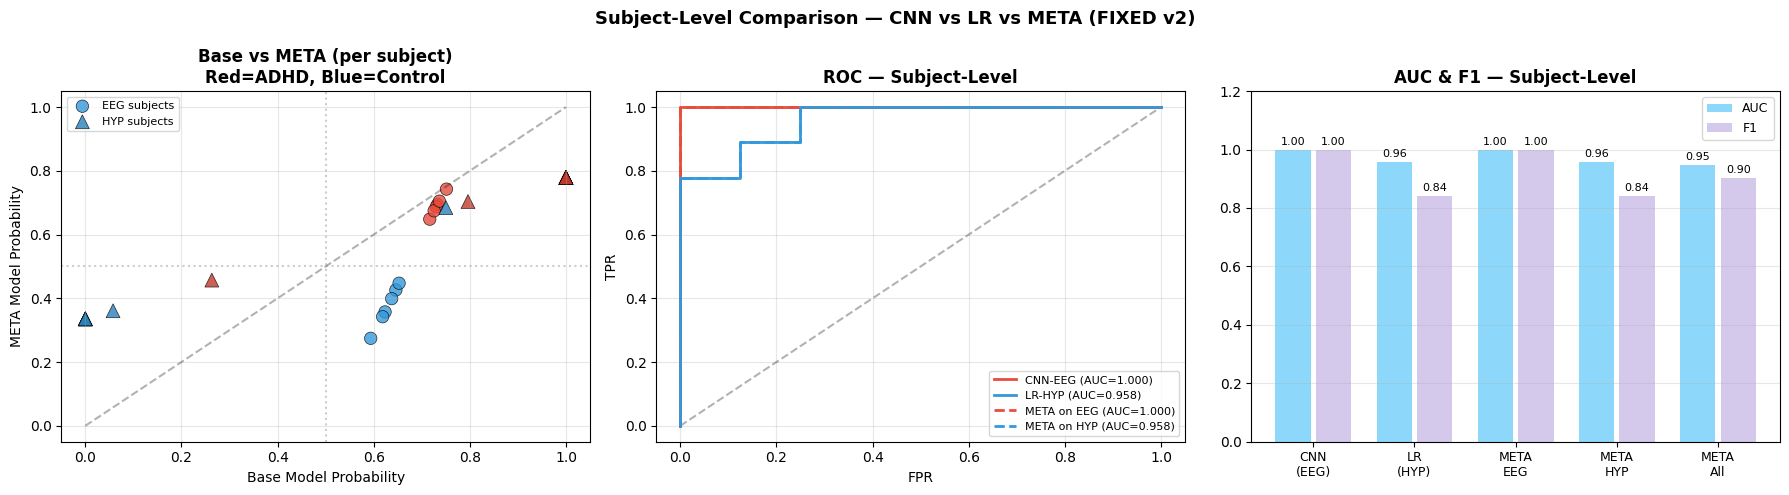

Done! All plots saved.


In [ ]:
# ─── Step 15: Subject-Level Visualization ───────────────────────────────────
fig3, axes3 = plt.subplots(1, 3, figsize=(18, 5))
fig3.suptitle('Subject-Level Comparison — CNN vs LR vs META (FIXED v2)',
              fontweight='bold', fontsize=13)

# Scatter: Base vs META probability per subject
colors_eeg = ['#E74C3C' if l==1 else '#3498DB' for l in subj_eeg_label]
axes3[0].scatter(subj_eeg_prob, meta_subj_eeg_prob,
                 c=colors_eeg, marker='o', s=80, alpha=0.8,
                 edgecolors='black', linewidths=0.5, label='EEG subjects')
colors_hyp = ['#C0392B' if l==1 else '#2980B9' for l in subj_hyp_label]
axes3[0].scatter(subj_hyp_prob, meta_subj_hyp_prob,
                 c=colors_hyp, marker='^', s=100, alpha=0.8,
                 edgecolors='black', linewidths=0.5, label='HYP subjects')
axes3[0].plot([0,1],[0,1],'k--', alpha=0.3)
axes3[0].axvline(0.5, color='gray', ls=':', alpha=0.4)
axes3[0].axhline(0.5, color='gray', ls=':', alpha=0.4)
axes3[0].set_xlabel('Base Model Probability')
axes3[0].set_ylabel('META Model Probability')
axes3[0].set_title('Base vs META (per subject)\nRed=ADHD, Blue=Control',
                   fontweight='bold')
axes3[0].legend(fontsize=8); axes3[0].grid(True, alpha=0.3)

# ROC subject-level
axes3[1].plot([0,1],[0,1],'k--', alpha=0.3)
styles = [
    (rs_cnn,      subj_eeg_prob,      '#E74C3C', '-',  'CNN-EEG'),
    (rs_lr,       subj_hyp_prob,      '#3498DB', '-',  'LR-HYP'),
    (rs_meta_eeg, meta_subj_eeg_prob, '#E74C3C', '--', 'META on EEG'),
    (rs_meta_hyp, meta_subj_hyp_prob, '#3498DB', '--', 'META on HYP'),
]
for r, _, color, ls, lbl in styles:
    axes3[1].plot(r['fpr'], r['tpr'], color=color, ls=ls, lw=2,
                  label=f'{lbl} (AUC={r["auc"]:.3f})')
axes3[1].set_title('ROC — Subject-Level', fontweight='bold')
axes3[1].set_xlabel('FPR'); axes3[1].set_ylabel('TPR')
axes3[1].legend(fontsize=8); axes3[1].grid(True, alpha=0.3)

# AUC + F1 bar
models_s = ['CNN\n(EEG)', 'LR\n(HYP)', 'META\nEEG', 'META\nHYP', 'META\nAll']
aucs4 = [rs_cnn['auc'], rs_lr['auc'], rs_meta_eeg['auc'], rs_meta_hyp['auc'], rs_meta_all['auc']]
f1s4  = [rs_cnn['f1'],  rs_lr['f1'],  rs_meta_eeg['f1'],  rs_meta_hyp['f1'],  rs_meta_all['f1']]
x4 = np.arange(len(models_s))
b1 = axes3[2].bar(x4 - 0.2, aucs4, 0.35, color='#81D4FA', alpha=0.9, label='AUC')
b2 = axes3[2].bar(x4 + 0.2, f1s4,  0.35, color='#D1C4E9', alpha=0.9, label='F1')
for bar, v in list(zip(b1, aucs4)) + list(zip(b2, f1s4)):
    axes3[2].text(bar.get_x()+bar.get_width()/2,
                  bar.get_height()+0.01,
                  f'{v:.2f}', ha='center', va='bottom', fontsize=8)
axes3[2].set_xticks(x4); axes3[2].set_xticklabels(models_s, fontsize=9)
axes3[2].set_ylim(0, 1.2)
axes3[2].set_title('AUC & F1 — Subject-Level', fontweight='bold')
axes3[2].legend(fontsize=9); axes3[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('subject_level_FIXED_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print('Done! All plots saved.')


In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Cross population FIXED v2.ipynb"